# 01 · Exploratory data analysis

What does PJM East demand look like, and what drives it? Reads `mart.features_hourly` (built by the SQL pipeline). Figures are saved to `docs/figures/` for the README.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.features import load_features, add_groups

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = add_groups(load_features())
print(df.shape, df["ts"].min(), "->", df["ts"].max())
print("imputed hours:", int(df["is_imputed"].sum()), "| outlier hours:", int(df["is_outlier"].sum()))
df[["ts", "load_mw", "temp_c", "humidity_pct", "wind_kmh"]].describe().round(1)

(145201, 28) 2002-01-09 00:00:00 -> 2018-08-03 00:00:00
imputed hours: 30 | outlier hours: 0


,ts,load_mw,temp_c,humidity_pct,wind_kmh
count,145201,145201.0,145201.0,145201.0,145201.0
mean,2010-04-22 00:00:00,32078.0,12.9,67.6,11.4
min,2002-01-09 00:00:00,14544.0,-21.9,16.0,0.0
25%,2006-03-01 12:00:00,27568.0,4.7,52.0,7.2
50%,2010-04-22 00:00:00,31419.0,13.4,68.0,10.4
75%,2014-06-12 12:00:00,35646.0,21.4,84.0,14.5
max,2018-08-03 00:00:00,62009.0,39.9,100.0,49.8
std,NaN,6467.0,10.3,19.3,5.7


## 1 · Long-run behaviour

,avg,peak,avg_yoy_%
year,,,
2002,31537.0,55934.0,NaN
2003,31697.0,53737.0,0.5
2004,32268.0,51962.0,1.8
2005,33308.0,59031.0,3.2
2006,32407.0,62009.0,-2.7
2007,33611.0,59437.0,3.7
2008,32928.0,59655.0,-2.0
2009,31849.0,55433.0,-3.3
2010,33099.0,59807.0,3.9


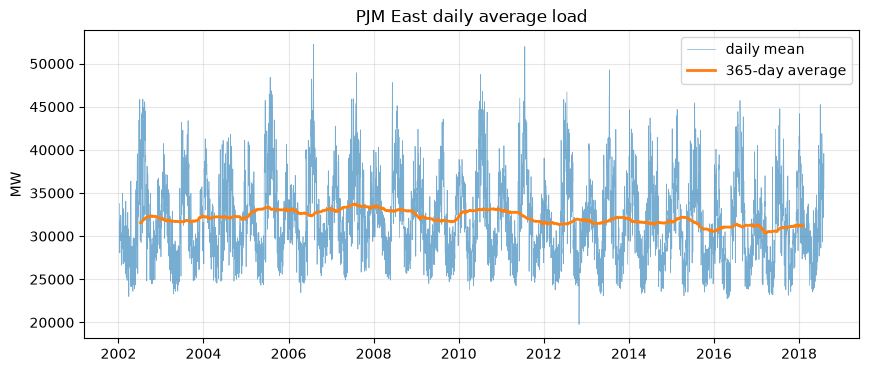

In [3]:
daily = df.set_index("ts")["load_mw"].resample("D").agg(["mean", "max"])
fig, ax = plt.subplots()
ax.plot(daily.index, daily["mean"], lw=0.5, alpha=0.6, label="daily mean")
ax.plot(daily.index, daily["mean"].rolling(365, center=True).mean(), lw=2, label="365-day average")
ax.set(title="PJM East daily average load", ylabel="MW"); ax.legend()
fig.savefig(FIG / "eda_daily_load.png", dpi=150, bbox_inches="tight")

yearly = df.groupby("year")["load_mw"].agg(avg="mean", peak="max").round(0)
yearly["avg_yoy_%"] = (yearly["avg"].pct_change() * 100).round(1)
yearly  # note: 2002 and 2018 are partial years

## 2 · Daily and seasonal shape

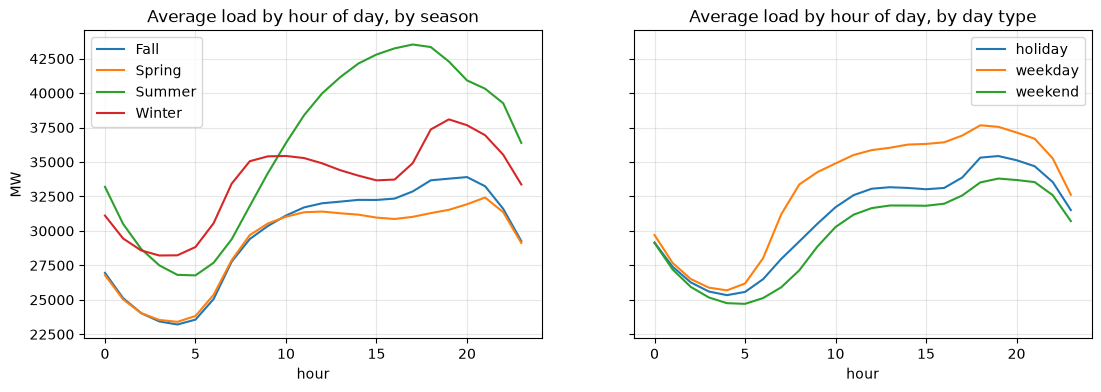

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for season, g in df.groupby("season"):
    axes[0].plot(g.groupby("hour_of_day")["load_mw"].mean(), label=season)
axes[0].set(title="Average load by hour of day, by season", xlabel="hour", ylabel="MW"); axes[0].legend()
for dt, g in df.groupby("day_type"):
    axes[1].plot(g.groupby("hour_of_day")["load_mw"].mean(), label=dt)
axes[1].set(title="Average load by hour of day, by day type", xlabel="hour"); axes[1].legend()
fig.savefig(FIG / "eda_hourly_profiles.png", dpi=150, bbox_inches="tight")

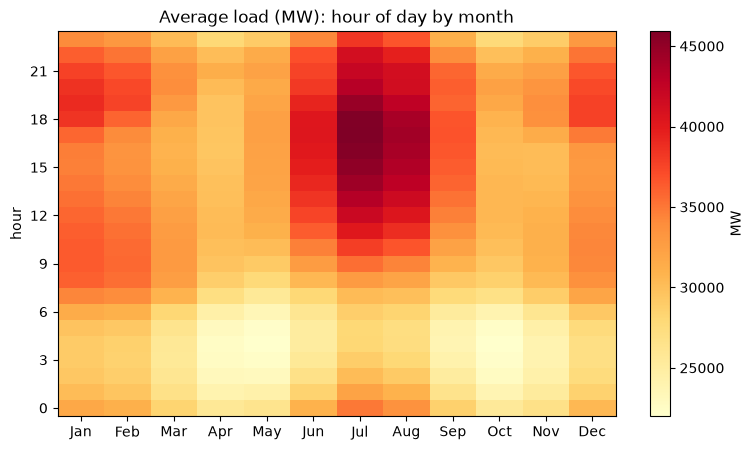

In [5]:
pivot = df.pivot_table(index="hour_of_day", columns="month", values="load_mw", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(pivot.values, aspect="auto", origin="lower", cmap="YlOrRd")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(0, 24, 3)); ax.set(title="Average load (MW): hour of day by month", ylabel="hour"); ax.grid(False)
fig.colorbar(im, label="MW")
fig.savefig(FIG / "eda_heatmap_hour_month.png", dpi=150, bbox_inches="tight")

## 3 · Temperature and load

correlation temp vs load: 0.243
(a U-shape means both heating and cooling demand; one number understates it)


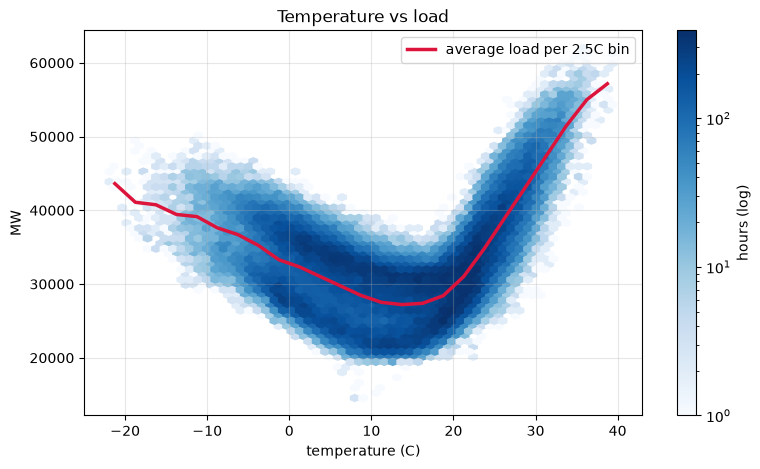

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(df["temp_c"], df["load_mw"], gridsize=60, mincnt=1, cmap="Blues", bins="log")
binned = df.groupby(pd.cut(df["temp_c"], np.arange(-25, 45, 2.5)), observed=True)["load_mw"].mean()
ax.plot([i.mid for i in binned.index], binned.values, color="crimson", lw=2.5, label="average load per 2.5C bin")
ax.set(title="Temperature vs load", xlabel="temperature (C)", ylabel="MW"); ax.legend()
fig.colorbar(hb, label="hours (log)")
fig.savefig(FIG / "eda_temp_vs_load.png", dpi=150, bbox_inches="tight")
print("correlation temp vs load:", round(df["temp_c"].corr(df["load_mw"]), 3))
print("(a U-shape means both heating and cooling demand; one number understates it)")

## 4 · Peaks

hours within 10% of the all-time peak: 0.16% of the time


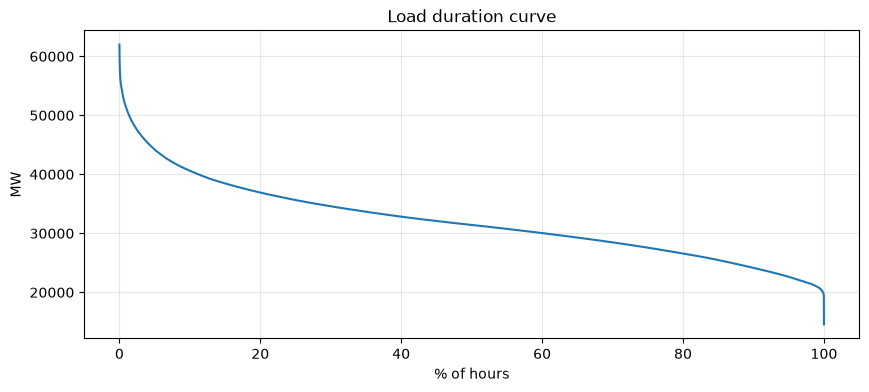

In [7]:
s = np.sort(df["load_mw"].values)[::-1]
x = np.arange(1, len(s) + 1) / len(s) * 100
fig, ax = plt.subplots()
ax.plot(x, s); ax.set(title="Load duration curve", xlabel="% of hours", ylabel="MW")
fig.savefig(FIG / "eda_load_duration.png", dpi=150, bbox_inches="tight")
print(f"hours within 10% of the all-time peak: {(s >= 0.9 * s.max()).mean() * 100:.2f}% of the time")

In [8]:
idx = df.groupby("date")["load_mw"].idxmax()
peaks = df.loc[idx, ["date", "hour_of_day", "load_mw", "temp_c", "day_type"]]
peaks.sort_values("load_mw", ascending=False).head(10).reset_index(drop=True)

,date,hour_of_day,load_mw,temp_c,day_type
0,2006-08-02,17,62009.0,36.2,weekday
1,2006-08-03,17,61796.0,36.1,weekday
2,2011-07-22,15,61646.0,39.6,weekday
3,2006-08-01,17,61643.0,35.7,weekday
4,2011-07-21,17,60689.0,36.2,weekday
5,2006-07-18,17,59943.0,33.0,weekday
6,2010-07-06,17,59807.0,39.0,weekday
7,2008-06-10,17,59655.0,34.4,weekday
8,2007-08-08,16,59437.0,35.4,weekday
9,2006-07-17,17,59183.0,36.5,weekday


In [9]:
peaks["peak_hour"] = peaks["hour_of_day"]
print("Share of daily peaks by hour of day (top 6 hours):")
(peaks["peak_hour"].value_counts(normalize=True).head(6) * 100).round(1)

Share of daily peaks by hour of day (top 6 hours):


peak_hour
19    21.7
18    17.5
17    15.3
20    13.9
21    11.4
8      5.1
Name: proportion, dtype: float64

## 5 · Is the past informative? (sanity check for the lag features)

In [10]:
df[["load_mw", "load_lag_24h", "load_lag_168h", "load_roll_7d", "temp_c"]].corr().round(3)

,load_mw,load_lag_24h,load_lag_168h,load_roll_7d,temp_c
load_mw,1.000,0.891,0.782,0.526,0.243
load_lag_24h,0.891,1.000,0.745,0.566,0.243
load_lag_168h,0.782,0.745,1.000,0.604,0.237
load_roll_7d,0.526,0.566,0.604,1.000,0.175
temp_c,0.243,0.243,0.237,0.175,1.000
